In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully")


All libraries imported successfully


In [17]:
df = pd.read_csv("smart_parking_usage_occupancy_analytics_demo_visualization.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (2800, 12)


,parking_id,zone,date_time,total_slots,occupied_slots,avg_parking_duration_minutes,vehicle_type,entry_count,exit_count,parking_fee_collected,violation_reported,occupancy_rate_percent
0,1,Mall,2024-01-01 00:00:00,191,122,170,Car,65,86,4268.46,Yes,63.87
1,2,Hospital,2024-01-01 01:00:00,169,34,96,Car,104,100,2791.18,No,20.12
2,3,Office,2024-01-01 02:00:00,215,79,91,Bike,55,82,3603.45,No,36.74
3,4,Hospital,2024-01-01 03:00:00,230,212,228,Bike,102,51,4490.34,No,92.17
4,5,Hospital,2024-01-01 04:00:00,110,101,218,SUV,13,7,4513.62,No,91.82


In [18]:
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

display(df.describe(include="all"))


Columns:
['parking_id', 'zone', 'date_time', 'total_slots', 'occupied_slots', 'avg_parking_duration_minutes', 'vehicle_type', 'entry_count', 'exit_count', 'parking_fee_collected', 'violation_reported', 'occupancy_rate_percent']

Data Types:
parking_id                        int64
zone                                str
date_time                           str
total_slots                       int64
occupied_slots                    int64
avg_parking_duration_minutes      int64
vehicle_type                        str
entry_count                       int64
exit_count                        int64
parking_fee_collected           float64
violation_reported                  str
occupancy_rate_percent          float64
dtype: object

Missing Values:
parking_id                      0
zone                            0
date_time                       0
total_slots                     0
occupied_slots                  0
avg_parking_duration_minutes    0
vehicle_type                    0
entry_coun

,parking_id,zone,date_time,total_slots,occupied_slots,avg_parking_duration_minutes,vehicle_type,entry_count,exit_count,parking_fee_collected,violation_reported,occupancy_rate_percent
count,2800.000000,2800,2800,2800.000000,2800.000000,2800.000000,2800,2800.000000,2800.000000,2800.000000,2800,2800.000000
unique,NaN,5,2800,NaN,NaN,NaN,4,NaN,NaN,NaN,2,NaN
top,NaN,Mall,2024-01-01 00:00:00,NaN,NaN,NaN,Car,NaN,NaN,NaN,No,NaN
freq,NaN,581,1,NaN,NaN,NaN,759,NaN,NaN,NaN,2381,NaN
mean,1400.500000,NaN,NaN,174.638571,105.407143,127.942857,NaN,61.775000,61.776786,2501.175457,NaN,65.433929
std,808.434702,NaN,NaN,71.057968,53.744748,64.514209,NaN,33.179184,32.875807,1453.113527,NaN,28.125252
min,1.000000,NaN,NaN,50.000000,10.000000,15.000000,NaN,5.000000,5.000000,50.780000,NaN,19.300000
25%,700.750000,NaN,NaN,113.000000,59.000000,72.000000,NaN,32.000000,33.000000,1223.860000,NaN,39.180000
50%,1400.500000,NaN,NaN,175.000000,98.000000,128.000000,NaN,61.000000,61.000000,2446.300000,NaN,72.070000
75%,2100.250000,NaN,NaN,234.000000,143.000000,183.000000,NaN,91.000000,89.250000,3800.657500,NaN,92.450000


In [19]:
numeric_columns = df.select_dtypes(include=np.number).columns

print("Negative values:")
for col in numeric_columns:
    count = (df[col] < 0).sum()
    if count > 0:
        print(col, ":", count)

Negative values:


In [20]:
capacity_errors = df[df["occupied_slots"] > df["total_slots"]]

print("Capacity errors:", len(capacity_errors))

display(
    capacity_errors[
        ["parking_id", "zone", "total_slots", "occupied_slots"]
    ].head(10)
)

Capacity errors: 0


,parking_id,zone,total_slots,occupied_slots


In [21]:
df = df.drop_duplicates().copy()

df["occupied_slots_original"] = df["occupied_slots"]

df["occupied_slots"] = np.minimum(
    df["occupied_slots"],
    df["total_slots"]
)

df["occupancy_rate_percent"] = (
    df["occupied_slots"] / df["total_slots"]
) * 100


df["occupancy_rate_percent"] = df["occupancy_rate_percent"].round(2)

In [22]:
df["capacity_violation_flag"] = (
    df["occupied_slots_original"] > df["total_slots"]
)

df["missing_flag"] = df.isnull().any(axis=1)

print("Capacity issues fixed:",
      df["capacity_violation_flag"].sum())

print("Rows with missing values:",
      df["missing_flag"].sum())

Capacity issues fixed: 0
Rows with missing values: 0


In [23]:
numeric_columns = df.select_dtypes(include="number").columns

for col in numeric_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

categorical_columns = df.select_dtypes(
    include=["object", "string", "category"]
).columns

for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled successfully.")


Missing values handled successfully.


In [24]:
df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")

df["hour"] = df["date_time"].dt.hour
df["date"] = df["date_time"].dt.date
print(df["date_time"].dtype)
print(df[["date_time", "hour", "date"]].head())
print(df.head())


datetime64[us]
            date_time  hour        date
0 2024-01-01 00:00:00     0  2024-01-01
1 2024-01-01 01:00:00     1  2024-01-01
2 2024-01-01 02:00:00     2  2024-01-01
3 2024-01-01 03:00:00     3  2024-01-01
4 2024-01-01 04:00:00     4  2024-01-01
   parking_id      zone           date_time  total_slots  occupied_slots  \
0           1      Mall 2024-01-01 00:00:00          191             122   
1           2  Hospital 2024-01-01 01:00:00          169              34   
2           3    Office 2024-01-01 02:00:00          215              79   
3           4  Hospital 2024-01-01 03:00:00          230             212   
4           5  Hospital 2024-01-01 04:00:00          110             101   

   avg_parking_duration_minutes vehicle_type  entry_count  exit_count  \
0                           170          Car           65          86   
1                            96          Car          104         100   
2                            91         Bike           55          82

In [25]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nMaximum Occupancy:")
print(df["occupancy_rate_percent"].max())

print("\nMinimum Occupancy:")
print(df["occupancy_rate_percent"].min())

Final Dataset Shape: (2800, 17)

Missing Values:
parking_id                      0
zone                            0
date_time                       0
total_slots                     0
occupied_slots                  0
avg_parking_duration_minutes    0
vehicle_type                    0
entry_count                     0
exit_count                      0
parking_fee_collected           0
violation_reported              0
occupancy_rate_percent          0
occupied_slots_original         0
capacity_violation_flag         0
missing_flag                    0
hour                            0
date                            0
dtype: int64

Duplicate Rows: 0

Maximum Occupancy:
96.0

Minimum Occupancy:
19.3


In [26]:
#analysis
total_records = len(df)
total_zones = df["zone"].nunique()
total_vehicle_types = df["vehicle_type"].nunique()

average_occupancy = df["occupancy_rate_percent"].mean()
total_revenue = df["parking_fee_collected"].sum()
total_violations = (df["violation_reported"] == "Yes").sum()
average_duration = df["avg_parking_duration_minutes"].mean()

print("SMART PARKING KPIs")
print("---------------------------")
print("Total Records:", total_records)
print("Total Zones:", total_zones)
print("Vehicle Types:", total_vehicle_types)
print("Average Occupancy:", round(average_occupancy, 2), "%")
print("Total Parking Revenue:", round(total_revenue, 2))
print("Total Violations:", total_violations)
print("Average Parking Duration:",
      round(average_duration, 2), "minutes")

SMART PARKING KPIs
---------------------------
Total Records: 2800
Total Zones: 5
Vehicle Types: 4
Average Occupancy: 65.43 %
Total Parking Revenue: 7003291.28
Total Violations: 419
Average Parking Duration: 127.94 minutes


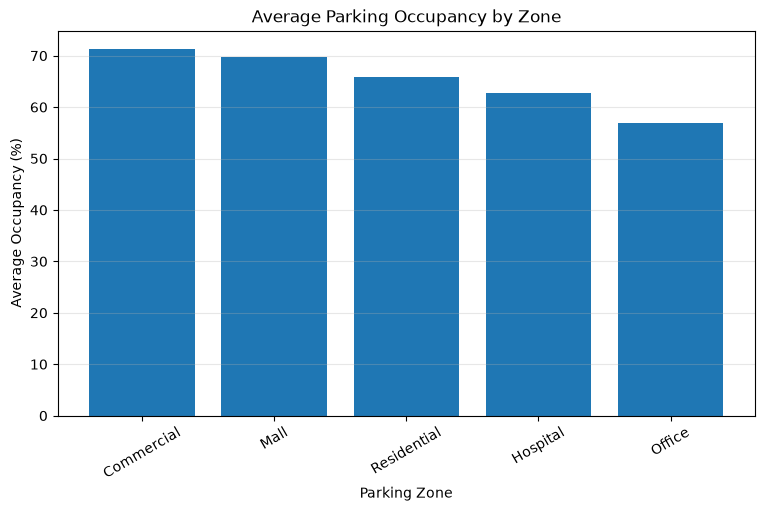

In [10]:
#plot 1
zone_analysis = (
    df.groupby("zone")["occupancy_rate_percent"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    zone_analysis.index,
    zone_analysis.values
)

plt.title("Average Parking Occupancy by Zone")
plt.xlabel("Parking Zone")
plt.ylabel("Average Occupancy (%)")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.show()

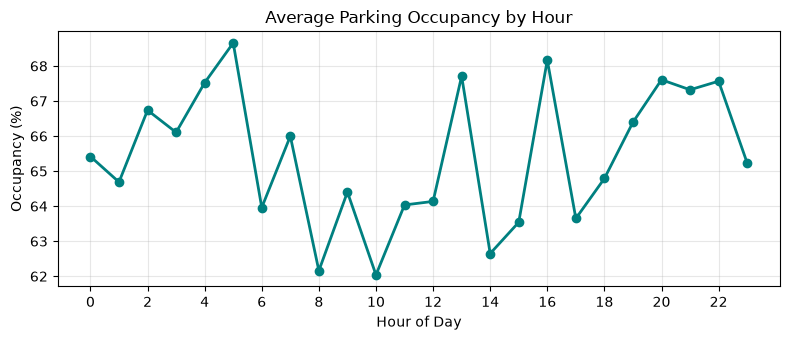

In [27]:
hour_analysis = (
    df.groupby("hour")["occupancy_rate_percent"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(8, 3.5))

plt.plot(
    hour_analysis.index,
    hour_analysis.values,
    marker="o",
    color="teal",
    linewidth=2
)

plt.title("Average Parking Occupancy by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Occupancy (%)")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

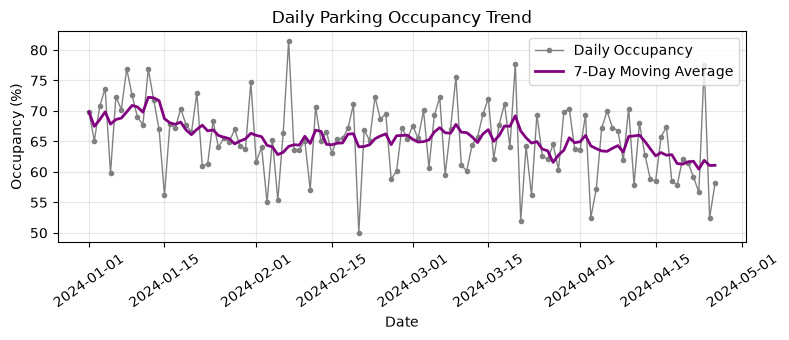

In [28]:
daily_analysis = (
    df.groupby("date")["occupancy_rate_percent"]
    .mean()
    .sort_index()
)

rolling_average = daily_analysis.rolling(
    window=7,
    min_periods=1
).mean()

plt.figure(figsize=(8, 3.5))

plt.plot(
    daily_analysis.index,
    daily_analysis.values,
    color="gray",
    marker=".",
    linewidth=1,
    label="Daily Occupancy"
)

plt.plot(
    daily_analysis.index,
    rolling_average.values,
    color="purple",
    linewidth=2,
    label="7-Day Moving Average"
)

plt.title("Daily Parking Occupancy Trend")
plt.xlabel("Date")
plt.ylabel("Occupancy (%)")
plt.xticks(rotation=35)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

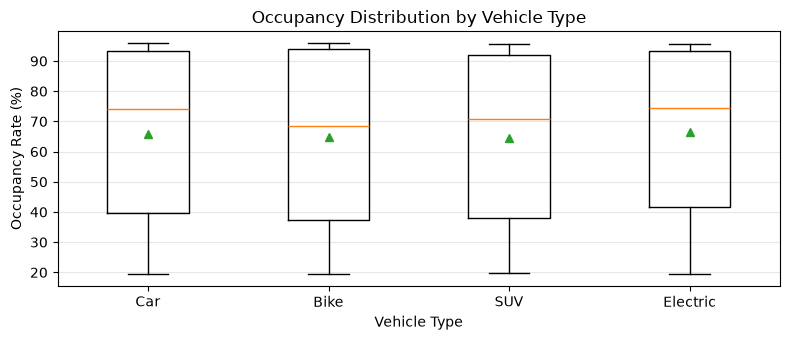

In [30]:
# Plot 4: Vehicle Occupancy - Box Plot

vehicle_types = df["vehicle_type"].dropna().unique()

vehicle_data = [
    df[df["vehicle_type"] == vehicle]["occupancy_rate_percent"].dropna()
    for vehicle in vehicle_types
]

plt.figure(figsize=(8, 3.5))

plt.boxplot(
    vehicle_data,
    tick_labels=vehicle_types,
    showmeans=True
)

plt.title("Occupancy Distribution by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Occupancy Rate (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

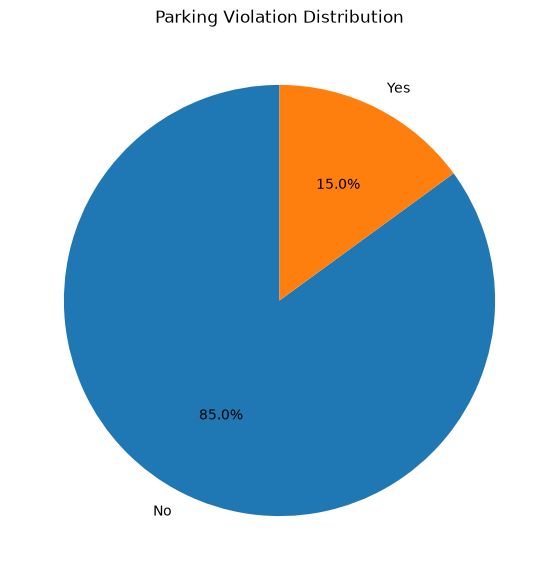

In [23]:
#plot5
violation_analysis = df["violation_reported"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    violation_analysis.values,
    labels=violation_analysis.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Parking Violation Distribution")

plt.show()

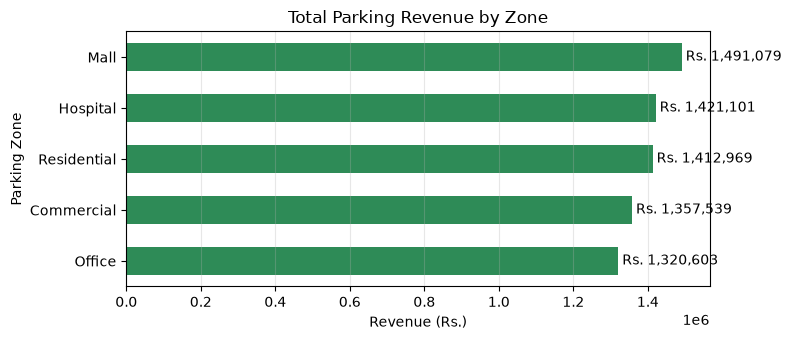

In [32]:
revenue_analysis = (
    df.groupby("zone")["parking_fee_collected"]
    .sum()
    .sort_values()
)

plt.figure(figsize=(8, 3.5))

bars = plt.barh(
    revenue_analysis.index,
    revenue_analysis.values,
    color="seagreen",
    height=0.55
)

for bar in bars:
    value = bar.get_width()

    plt.text(
        value,
        bar.get_y() + bar.get_height()/2,
        f" Rs. {value:,.0f}",
        va="center"
    )

plt.title("Total Parking Revenue by Zone")
plt.xlabel("Revenue (Rs.)")
plt.ylabel("Parking Zone")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

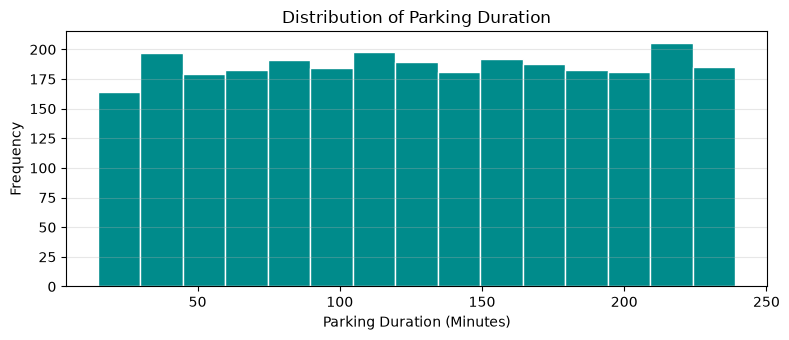

In [33]:
duration_data = (
    df["avg_parking_duration_minutes"]
    .dropna()
)

plt.figure(figsize=(8, 3.5))

plt.hist(
    duration_data,
    bins=15,
    color="darkcyan",
    edgecolor="white"
)

plt.title("Distribution of Parking Duration")
plt.xlabel("Parking Duration (Minutes)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

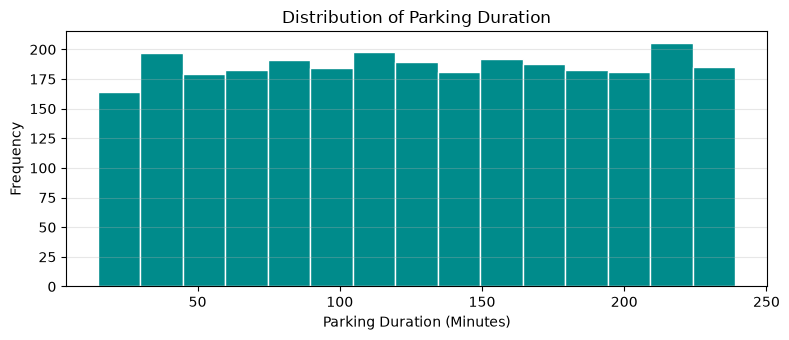

In [34]:
duration_data = (
    df["avg_parking_duration_minutes"]
    .dropna()
)

plt.figure(figsize=(8, 3.5))

plt.hist(
    duration_data,
    bins=15,
    color="darkcyan",
    edgecolor="white"
)

plt.title("Distribution of Parking Duration")
plt.xlabel("Parking Duration (Minutes)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

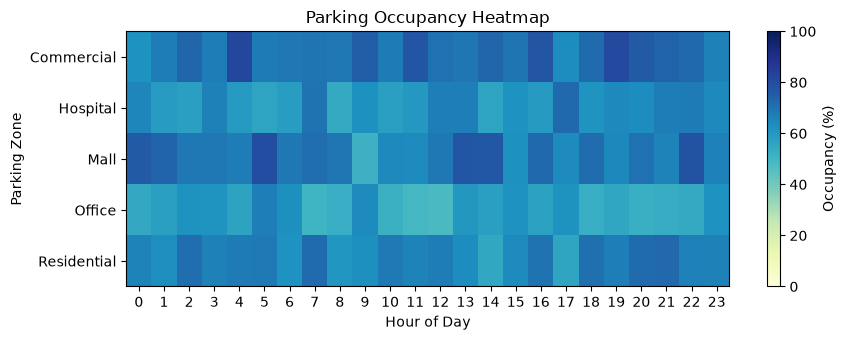

In [35]:
heatmap_data = df.pivot_table(
    index="zone",
    columns="hour",
    values="occupancy_rate_percent",
    aggfunc="mean"
)

plt.figure(figsize=(9, 3.5))

plt.imshow(
    heatmap_data,
    aspect="auto",
    cmap="YlGnBu",
    interpolation="nearest",
    vmin=0,
    vmax=100
)

plt.colorbar(label="Occupancy (%)")

plt.xticks(
    np.arange(len(heatmap_data.columns)),
    heatmap_data.columns
)

plt.yticks(
    np.arange(len(heatmap_data.index)),
    heatmap_data.index
)

plt.xlabel("Hour of Day")
plt.ylabel("Parking Zone")
plt.title("Parking Occupancy Heatmap")

plt.tight_layout()
plt.show()

In [31]:
#saving
df.to_csv(
    "smart_parking_cleaned_data.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [37]:
#exporting to excel
with pd.ExcelWriter(
    "smart_parking_analysis.xlsx",
    engine="openpyxl"
) as writer:

    df.to_excel(
        writer,
        sheet_name="Cleaned Data",
        index=False
    )

    zone_summary.to_excel(
        writer,
        sheet_name="Zone Analysis",
        index=False
    )

    vehicle_analysis.reset_index().to_excel(
        writer,
        sheet_name="Vehicle Analysis",
        index=False
    )

    hour_analysis.reset_index().to_excel(
        writer,
        sheet_name="Hourly Analysis",
        index=False
    )

    daily_analysis.reset_index().to_excel(
        writer,
        sheet_name="Daily Analysis",
        index=False
    )

print("Analysis Excel file created successfully.")

Analysis Excel file created successfully.
